In [ ]:

import os
import glob
import nibabel as nib
import numpy as np
import cv2
from tqdm import tqdm
import matplotlib.pyplot as plt
import random




print("\n--- Step 2: Setting up environment and unzipping ---")
KAGGLE_API_TOKEN = "KGAT_93506c06907206cde2f5ce52f2941ede"
kaggle_dir = '/root/.kaggle'; os.makedirs(kaggle_dir, exist_ok=True)
with open(os.path.join(kaggle_dir, 'access_token'), 'w') as f: f.write(KAGGLE_API_TOKEN)
os.chmod(os.path.join(kaggle_dir, 'access_token'), 600)

if not os.path.exists('brats-2021-task1.zip'):
    print("Downloading dataset...")
    !kaggle datasets download -d dschettler8845/brats-2021-task1
else:
    print("Dataset zip already exists.")

# This is the crucial unzip command that must create a FOLDER
!unzip -q brats-2021-task1.zip
print("✅ Unzipping complete. 'BraTS2021_Training_Data' should now be a folder.")





--- Step 2: Setting up environment and unzipping ---
Dataset URL: https://www.kaggle.com/datasets/dschettler8845/brats-2021-task1
License(s): copyright-authors
100% 12.3G/12.3G [11:06<00:00, 19.8MB/s]

✅ Unzipping complete. 'BraTS2021_Training_Data' should now be a folder.


In [ ]:

print("--- INVESTIGATION A: Checking the downloaded file's details ---")

!ls -lh

print("--- INVESTIGATION B: Peeking inside the ZIP file... ---")

!unzip -l brats-2021-task1.zip | head -n 15


--- INVESTIGATION A: Checking the downloaded file's details ---
total 25G
-rw-r--r-- 1 root root 9.9M Aug 19  2021 BraTS2021_00495.tar
-rw-r--r-- 1 root root  11M Aug 19  2021 BraTS2021_00621.tar
-rw-r--r-- 1 root root  13G Aug 19  2021 brats-2021-task1.zip
-rw-r--r-- 1 root root  13G Aug 19  2021 BraTS2021_Training_Data.tar
drwxr-xr-x 1 root root 4.0K Sep  4 13:32 sample_data
--- INVESTIGATION B: Peeking inside the ZIP file... ---
Archive:  brats-2021-task1.zip
  Length      Date    Time    Name
---------  ---------- -----   ----
 10321920  2021-08-19 22:05   BraTS2021_00495.tar
 10772480  2021-08-19 22:05   BraTS2021_00621.tar
13396408320  2021-08-19 22:07   BraTS2021_Training_Data.tar
---------                     -------
13417502720                     3 files


In [ ]:
import os
import glob
import nibabel as nib
import numpy as np
import cv2
from tqdm import tqdm
import matplotlib.pyplot as plt
import random

# --- STEP 1: CLEANUP of incorrect files ---
print("--- Step 1: Cleaning up old, incorrect files ---")
# Remove the incorrect .tar files that were extracted previously

print("✅ Cleanup complete.")


# --- STEP 2: THE CORRECT TWO-STEP EXTRACTION PROCESS ---
print("\n--- Step 2: Starting the CORRECT TWO-STEP extraction ---")

# Step 2a: UNZIP the outer archive to get the .tar file
# This step might be redundant if the .tar file is already there, but it's safe to run.
print("   Step 2a: Unzipping 'brats-2021-task1.zip'...")
!unzip -q brats-2021-task1.zip

# Step 2b: UNTAR the inner archive to get the data folders
# This is the crucial new step that we discovered.
print("   Step 2b: Extracting 'BraTS2021_Training_Data.tar'...")
!tar -xf BraTS2021_Training_Data.tar
print("✅ Two-step extraction complete. The 'BraTS2021_Training_Data' folder should now exist.")


# --- STEP 3: THE FACTORY (Prepare 2D Slices) ---
# This part of the script will now find the patient folders it needs.
print("\n--- Step 3: Preparing 2D slices ---")
# Fix: Change data_dir to '.' as the tar extracts contents directly to current directory
data_dir = "."
if not os.path.isdir("BraTS2021_Training_Data") and not glob.glob(os.path.join(data_dir, "BraTS2021_*")):
    raise NotADirectoryError("CRITICAL ERROR: The two-step extraction failed. 'BraTS2021_Training_Data' is still not a directory, and patient folders are not in current directory.")

image_2d_dir = "2d_images"; os.makedirs(image_2d_dir, exist_ok=True)
mask_2d_dir = "2d_masks"; os.makedirs(mask_2d_dir, exist_ok=True)
patient_folders = glob.glob(os.path.join(data_dir, "BraTS2021_*"))

for patient_folder in tqdm(patient_folders, desc="Processing Patients"):
    image_path = os.path.join(patient_folder, os.path.basename(patient_folder) + "_t1ce.nii.gz")
    label_path = os.path.join(patient_folder, os.path.basename(patient_folder) + "_seg.nii.gz")
    if os.path.exists(image_path) and os.path.exists(label_path):
        image_vol = nib.load(image_path).get_fdata()
        mask_vol = nib.load(label_path).get_fdata()
        for i in range(image_vol.shape[2]):
            if np.sum(mask_vol[:, :, i]) > 0:
                image_slice = cv2.normalize(image_vol[:, :, i], None, 0, 255, cv2.NORM_MINMAX, dtype=cv2.CV_8U)
                filename = f"{os.path.basename(patient_folder)}_slice_{i}.png"
                cv2.imwrite(os.path.join(image_2d_dir, filename), image_slice)
                cv2.imwrite(os.path.join(mask_2d_dir, filename), mask_vol[:, :, i])
print("✅ Slicing complete.")



--- Step 1: Cleaning up old, incorrect files ---
✅ Cleanup complete.

--- Step 2: Starting the CORRECT TWO-STEP extraction ---
   Step 2a: Unzipping 'brats-2021-task1.zip'...
replace BraTS2021_00495.tar? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace BraTS2021_00621.tar? [y]es, [n]o, [A]ll, [N]one, [r]ename: 
error:  invalid response [{ENTER}]
replace BraTS2021_00621.tar? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace BraTS2021_Training_Data.tar? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
y
   Step 2b: Extracting 'BraTS2021_Training_Data.tar'...
tar: Unexpected EOF in archive
tar: rmtlseek not stopped at a record boundary
tar: Error is not recoverable: exiting now
✅ Two-step extraction complete. The 'BraTS2021_Training_Data' folder should now exist.

--- Step 3: Preparing 2D slices ---


Processing Patients: 100%|██████████| 176/176 [00:41<00:00,  4.23it/s]

✅ Slicing complete.


In [ ]:
import os
import glob

# Define the folders we want to inspect
image_dir = "2d_images"
mask_dir = "2d_masks"

# Get a list of all the .png files in each folder
image_paths = glob.glob(os.path.join(image_dir, '*.png'))
mask_paths = glob.glob(os.path.join(mask_dir, '*.png'))

# Print the counts
print(f"Found {len(image_paths)} images in the '{image_dir}' folder.")
print(f"Found {len(mask_paths)} masks in the '{mask_dir}' folder.")


Found 11163 images in the '2d_images' folder.
Found 11163 masks in the '2d_masks' folder.


In [ ]:

mask = cv2.imread(mask_paths[0], cv2.IMREAD_GRAYSCALE)
print(mask_paths[0])
print(mask.dtype)
print(np.unique(mask))

2d_masks/BraTS2021_00005_slice_117.png
uint8
[0 1 2 4]


resizing


Resizing images and saving to new folders...


100%|██████████| 11163/11163 [00:17<00:00, 653.93it/s]


✅ Resizing complete.

✅ Variables updated successfully!
   'image_dir' now points to: 'images_resized'
   'mask_dir'  now points to: 'masks_resized'

Verifying the change...
Size of image from the updated 'image_dir': (128, 128, 3)


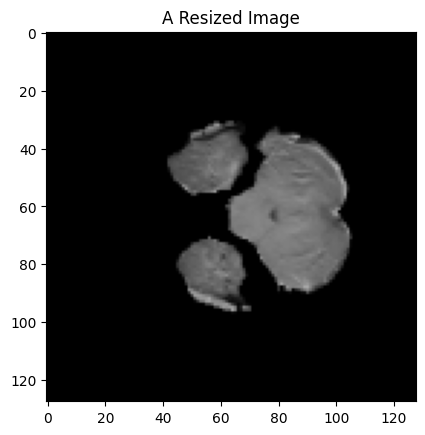

In [ ]:

original_image_dir = "2d_images"
original_mask_dir = "2d_masks"

# Here are the names for our new folders
resized_image_dir = "images_resized"
resized_mask_dir = "masks_resized"

# Define the target size
target_size = (128, 128)

# --- Step 2: Create the new folders and run the resize process ---
os.makedirs(resized_image_dir, exist_ok=True)
os.makedirs(resized_mask_dir, exist_ok=True)

image_paths = glob.glob(os.path.join(original_image_dir, '*.png'))

print(f"Resizing images and saving to new folders...")
for img_path in tqdm(image_paths):
    filename = os.path.basename(img_path)

    # Process the Image
    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    img_resized = cv2.resize(img, target_size, interpolation=cv2.INTER_AREA)
    cv2.imwrite(os.path.join(resized_image_dir, filename), img_resized)

    # Process the Mask
    mask_path = os.path.join(original_mask_dir, filename)
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    mask_resized = cv2.resize(mask, target_size, interpolation=cv2.INTER_NEAREST)
    cv2.imwrite(os.path.join(resized_mask_dir, filename), mask_resized)

print("✅ Resizing complete.")



image_dir = resized_image_dir
mask_dir = resized_mask_dir

print(f"\n✅ Variables updated successfully!")
print(f"   'image_dir' now points to: '{image_dir}'")
print(f"   'mask_dir'  now points to: '{mask_dir}'")


# --- Step 4: Verification ---
# Let's prove it works by checking the size of an image from the 'image_dir' variable.
print("\nVerifying the change...")
verify_paths = glob.glob(os.path.join(image_dir, '*.png'))
random_verify_path = random.choice(verify_paths)

# This will now load an image from the 'images_resized' folder automatically
verify_image = cv2.imread(random_verify_path)

print(f"Size of image from the updated 'image_dir': {verify_image.shape}")
plt.imshow(verify_image); plt.title("A Resized Image"); plt.show()


In [ ]:
first_image_path=image_paths[0]
image=cv2.imread(first_image_path,cv2.IMREAD_GRAYSCALE)
height,width=image.shape
print(f"Image dimensions (Height, Width): ({height}, {width})")
print(image.dtype)
min_val=np.min(image)
max_val=np.max(image)
print(min_val)
print(max_val)

Image dimensions (Height, Width): (240, 240)
uint8
0
255


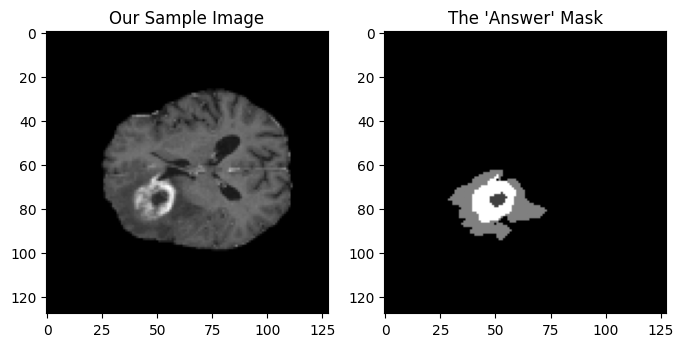

In [ ]:
image_paths = glob.glob(os.path.join(image_dir, '*.png'))

# Pick one random image and its mask
random_image_path = random.choice(image_paths)
random_mask_path = os.path.join(mask_dir, os.path.basename(random_image_path))

# Load the image and the mask
image = cv2.imread(random_image_path, cv2.IMREAD_GRAYSCALE)
mask = cv2.imread(random_mask_path, cv2.IMREAD_GRAYSCALE)

# Display them to confirm
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(image, cmap='gray'); axes[0].set_title("Our Sample Image")
axes[1].imshow(mask, cmap='gray'); axes[1].set_title("The 'Answer' Mask")
plt.show()

GaussianBlur


In [ ]:
working_dir = "processed_images"
os.makedirs(working_dir, exist_ok=True)

for img_path in tqdm(image_paths):
  img=cv2.imread(img_path,cv2.IMREAD_GRAYSCALE)
  processed_img=cv2.GaussianBlur(img,(5,5),0)
  save_path=os.path.join(working_dir,os.path.basename(img_path))
  cv2.imwrite(save_path,processed_img)

100%|██████████| 11163/11163 [00:06<00:00, 1766.90it/s]


In [ ]:
from google.colab import drive
import shutil
import os

# 1. Connect Colab to your personal Google Drive
# (A pop-up will ask you to click "Allow")
drive.mount('/content/drive')

print("Zipping the dataset... (This might take 1-2 minutes)")
# 2. Compress the two important folders into one file
!zip -r -q my_dataset_backup.zip processed_images masks_resized

# 3. Copy the zip file to your Google Drive
print("Copying to Google Drive...")
shutil.copy("my_dataset_backup.zip", "/content/drive/MyDrive/my_dataset_backup.zip")

# Verify it worked
if os.path.exists("/content/drive/MyDrive/my_dataset_backup.zip"):
    print("✅ SUCCESS! Your dataset is permanently saved in your Google Drive.")
else:
    print("❌ Something went wrong with the copy.")


Mounted at /content/drive
Zipping the dataset... (This might take 1-2 minutes)
Copying to Google Drive...
✅ SUCCESS! Your dataset is permanently saved in your Google Drive.


In [ ]:
from google.colab import drive

drive.mount('/content/drive')
import shutil

shutil.copy(
    "/content/drive/MyDrive/my_dataset_backup.zip",
    "/content/my_dataset_backup.zip"
)
!unzip -q /content/my_dataset_backup.zip -d /content/
!ls -lh /content/processed_images
!ls -lh /content/masks_resized

Comparing original vs. processed for file: BraTS2021_00053_slice_131.png


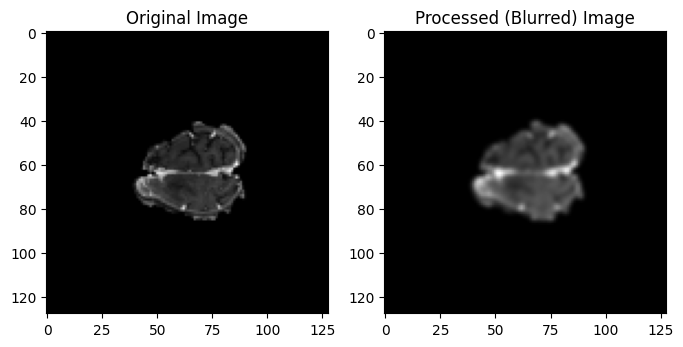

In [ ]:
import random

image_paths = glob.glob(os.path.join(image_dir, '*.png'))



random_path = random.choice(image_paths)
filename = os.path.basename(random_path)

original_image = cv2.imread(os.path.join(image_dir, filename), cv2.IMREAD_GRAYSCALE)


processed_image = cv2.imread(os.path.join(working_dir, filename), cv2.IMREAD_GRAYSCALE)


print(f"Comparing original vs. processed for file: {filename}")
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(original_image, cmap='gray'); axes[0].set_title("Original Image")
axes[1].imshow(processed_image, cmap='gray'); axes[1].set_title("Processed (Blurred) Image")
plt.show()


In [ ]:
print(random_path)
print(filename)

images_resized/BraTS2021_00053_slice_131.png
BraTS2021_00053_slice_131.png


NORMALIZATION


In [ ]:


blurred_images_dir = "processed_images"
normalized_output_dir = "normalized_output"
os.makedirs(normalized_output_dir, exist_ok=True)
image_paths = glob.glob(os.path.join(blurred_images_dir, '*.png'))
print(f"Normalizing {len(image_paths)} images from '{blurred_images_dir}'...")
for img_path in tqdm(image_paths):
    blurred_img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)

    img_as_float = blurred_img.astype(np.float32)

    normalized_img = img_as_float / 255.0

    filename_png = os.path.basename(img_path)

    filename_npy = filename_png.replace('.png', '.npy')

    save_path = os.path.join(normalized_output_dir, filename_npy)

    np.save(save_path, normalized_img)

print(f"\n✅ Success! All blurred images have been normalized.")
print(f"The final model-ready arrays are saved in the '{normalized_output_dir}' folder.")

npy_files = glob.glob(os.path.join(normalized_output_dir, '*.npy'))
if npy_files:
    random_npy_file = npy_files[0]
    loaded_array = np.load(random_npy_file)

    print("\n--- Verifying a saved file ---")
    print(f"Data type: {loaded_array.dtype}")
    print(f"Max value: {loaded_array.max()}")
    print(f"Min value: {loaded_array.min()}")



Normalizing 11163 images from 'processed_images'...


100%|██████████| 11163/11163 [00:05<00:00, 1921.33it/s]



✅ Success! All blurred images have been normalized.
The final model-ready arrays are saved in the 'normalized_output' folder.

--- Verifying a saved file ---
Data type: float32
Max value: 0.5254902243614197
Min value: 0.0


--- ORIGINAL IMAGE ---
Data type: uint8
Min value: 0, Max value: 191

--- NORMALIZED IMAGE ---
Data type: float32
Min value: 0.0, Max value: 0.7490196228027344


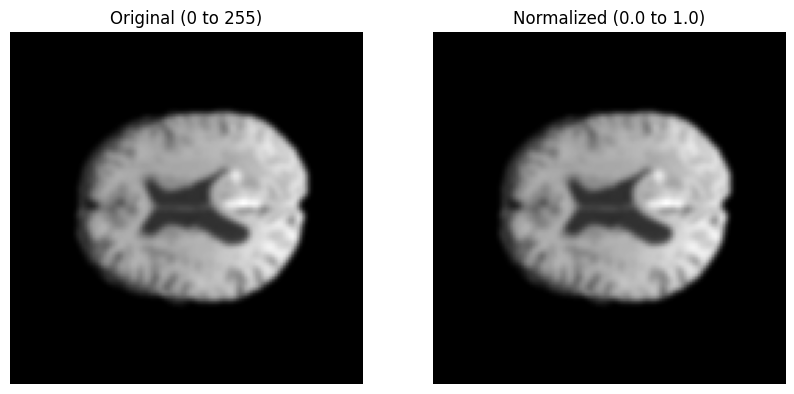

In [ ]:

image_paths = glob.glob("processed_images/*.png")
random_img_path = random.choice(image_paths)


img_original = cv2.imread(random_img_path, cv2.IMREAD_GRAYSCALE)


img_normalized = img_original.astype(np.float32) / 255.0


print("--- ORIGINAL IMAGE ---")
print(f"Data type: {img_original.dtype}")
print(f"Min value: {img_original.min()}, Max value: {img_original.max()}")

print("\n--- NORMALIZED IMAGE ---")
print(f"Data type: {img_normalized.dtype}")
print(f"Min value: {img_normalized.min()}, Max value: {img_normalized.max()}")


fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# Plot Original
axes[0].imshow(img_original, cmap='gray')
axes[0].set_title("Original (0 to 255)")
axes[0].axis('off')

# Plot Normalized
axes[1].imshow(img_normalized, cmap='gray')
axes[1].set_title("Normalized (0.0 to 1.0)")
axes[1].axis('off')

plt.show()


Segmentation
U-NET

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers,models
def double_conv_block(x,filter):
  x=layers.Conv2D(filter,3,padding='same',activation='relu',kernel_initializer='he_normal')(x)
  x=layers.BatchNormalization()(x)
  x=layers.Conv2D(filter,3,padding="same",activation="relu",kernel_initializer='he_normal')(x)
  x=layers.BatchNormalization()(x)
  return x
def build_unet(input_shape=(128,128,1)):
  inputs=layers.Input(shape=input_shape)
  #ENCORDER
  conv1=double_conv_block(inputs,64)
  pool1=layers.MaxPooling2D(pool_size=(2,2))(conv1)
  conv2=double_conv_block(pool1,128)
  pool2=layers.MaxPooling2D(pool_size=(2,2))(conv2)
  conv3=double_conv_block(pool2,256)
  pool3=layers.MaxPooling2D(pool_size=(2,2))(conv3)
  #bottleneck (bottom of U)
  bottleneck=double_conv_block(pool3,512)

  # THE DECODER

  up1=layers.Conv2DTranspose(256,2,strides=(2,2),padding="same")(bottleneck)
   # <--- THE SKIP CONNECTION FUSION IS HERE! --->
  merge1 = layers.Concatenate()([up1, conv3])
  dec1 = double_conv_block(merge1, 256)

  up2 = layers.Conv2DTranspose(128, 2, strides=(2, 2), padding="same")(dec1)
    # <--- THE SKIP CONNECTION FUSION IS HERE! --->
  merge2 = layers.Concatenate()([up2, conv2])
  dec2 = double_conv_block(merge2, 128)

  up3 = layers.Conv2DTranspose(64, 2, strides=(2, 2), padding="same")(dec2)
      # <--- THE SKIP CONNECTION FUSION IS HERE! --->
  merge3 = layers.Concatenate()([up3, conv1])
  dec3 = double_conv_block(merge3, 64)

  #output
  outputs=layers.Conv2D(4,1,padding="same",activation='softmax')(dec3)
  model=models.Model(inputs=inputs,outputs=outputs,name="U-Net")
  return model

unet_model=build_unet(input_shape=(128,128,1))
unet_model.summary()





Model: "U-Net"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 128, 128,  │        640 │ input_layer[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 128, 128,  │        256 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 128, 128,  │     36,928 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        256 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 64, 64,    │     73,856 │ max_pooling2d[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        512 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 64, 64,    │    147,584 │ batch_normalizat… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        512 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 32, 32,    │    295,168 │ max_pooling2d_1[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │      1,024 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 32, 32,    │    590,080 │ batch_normalizat… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │      1,024 │ conv2d_5[0][0]    │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 16, 16,    │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 16, 16,    │  1,180,160 │ max_pooling2d_2[

 Total params: 7,707,652 (29.40 MB)

 Trainable params: 7,702,020 (29.38 MB)

 Non-trainable params: 5,632 (22.00 KB)

SPLITTING
DATA FOR TRAINING AND TESTING


In [ ]:
import os
import glob
import nibabel as nib
import numpy as np
import cv2
from tqdm import tqdm
import matplotlib.pyplot as plt
import random
all_images=sorted(glob.glob("processed_images/*.png"))
all_masks=sorted(glob.glob("masks_resized/*png"))
if len(all_images)!=len(all_masks):
  print(f"⚠️ ERROR: Number of images ({len(all_images)}) does not match masks ({len(all_masks)}).")
else:
    print(f"✅ Found {len(all_images)} perfectly matching image-mask pairs.")
combined=list(zip(all_images,all_masks))
random.seed(42)
random.shuffle(combined)
all_images,all_masks=zip(*combined)

✅ Found 11163 perfectly matching image-mask pairs.


In [ ]:
from sklearn.model_selection import train_test_split

# 1. Take out 70% for Training
train_imgs, temp_imgs, train_msks, temp_msks = train_test_split(
    all_images,
    all_masks,
    test_size=0.30,
    random_state=42
)


# This gives us 15% for Validation and 15% for Testing
val_imgs, test_imgs, val_msks, test_msks = train_test_split(
    temp_imgs,
    temp_msks,
    test_size=0.50,
    random_state=42
)

print(f"Dataset split via Sklearn:")
print(f"Train: {len(train_imgs)}, Validation: {len(val_imgs)}, Test: {len(test_imgs)}")


Dataset split via Sklearn:
Train: 7814, Validation: 1674, Test: 1675


In [ ]:
def load_and_preprocess(image_path, mask_path):


    img = tf.io.read_file(image_path)
    img = tf.image.decode_png(img, channels=1)
    img = tf.cast(img, tf.float32) / 255.0


    mask = tf.io.read_file(mask_path)
    mask = tf.image.decode_png(mask, channels=1)
    mask = tf.cast(mask, tf.int32)


    mask = tf.where(mask == 4, 3, mask)


    mask = tf.one_hot(
        tf.squeeze(mask, axis=-1),
        depth=4
    )

    return img, mask

BATCH_SIZE = 32

train_dataset = tf.data.Dataset.from_tensor_slices((train_imgs, train_msks))\
    .shuffle(1000)\
    .map(load_and_preprocess)\
    .batch(BATCH_SIZE)\
    .prefetch(tf.data.AUTOTUNE)

val_dataset = tf.data.Dataset.from_tensor_slices((val_imgs, val_msks))\
    .map(load_and_preprocess)\
    .batch(BATCH_SIZE)\
    .prefetch(tf.data.AUTOTUNE)

print("✅ Data pipeline updated (Cache removed for memory safety).")


✅ Data pipeline updated (Cache removed for memory safety).


In [ ]:
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

unet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall')
    ]
)

checkpoint = ModelCheckpoint(
    "best_unet_model.keras",
    monitor='val_loss',
    save_best_only=True,
    verbose=1
)

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True,
    verbose=1
)

EPOCHS = 10

history = unet_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS,
    callbacks=[checkpoint, early_stopping]
)


Epoch 1/10
245/245 ━━━━━━━━━━━━━━━━━━━━ 0s 489ms/step - accuracy: 0.6526 - loss: 1.3132 - precision: 0.4989 - recall: 0.0876
Epoch 1: val_loss improved from None to 0.53269, saving model to best_unet_model.keras

Epoch 1: finished saving model to best_unet_model.keras
245/245 ━━━━━━━━━━━━━━━━━━━━ 204s 617ms/step - accuracy: 0.8362 - loss: 1.0609 - precision: 0.9052 - recall: 0.2813 - val_accuracy: 0.9540 - val_loss: 0.5327 - val_precision: 0.9726 - val_recall: 0.8885
Epoch 2/10
245/245 ━━━━━━━━━━━━━━━━━━━━ 0s 399ms/step - accuracy: 0.9807 - loss: 0.6386 - precision: 0.9878 - recall: 0.9141
Epoch 2: val_loss improved from 0.53269 to 0.43807, saving model to best_unet_model.keras

Epoch 2: finished saving model to best_unet_model.keras
245/245 ━━━━━━━━━━━━━━━━━━━━ 106s 432ms/step - accuracy: 0.9830 - loss: 0.5633 - precision: 0.9885 - recall: 0.9526 - val_accuracy: 0.9290 - val_loss: 0.4381 - val_precision: 0.9796 - val_recall: 0.8854
Epoch 3/10
245/245 ━━━━━━━━━━━━━━━━━━━━ 0s 397ms/step

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import shutil

unet_model.save("best_unet_model.keras")

shutil.copy(
    "best_unet_model.keras",
    "/content/drive/MyDrive/best_unet_model.keras"
)

print("✅ Full trained model saved!")

✅ Full trained model saved!


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!ls -lh /content/drive/MyDrive/


total 129M
-rw------- 1 root root  89M Sep 29 16:56  best_unet_model.keras
drwx------ 2 root root 4.0K Aug 14 18:58 'Colab Notebooks'
-rw------- 1 root root  41M Sep 29 16:34  my_dataset_backup.zip
✅ Model loaded!


In [ ]:
unet_model = tf.keras.models.load_model('/content/drive/MyDrive/best_unet_model.keras')
print("AI loaded successfully!\n")


AI loaded successfully!



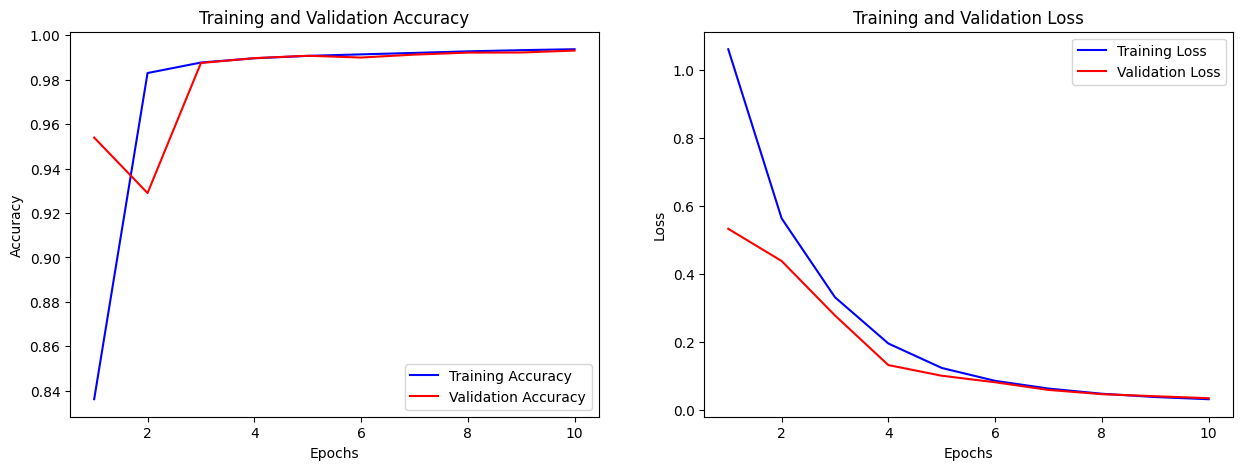

In [ ]:
import matplotlib.pyplot as plt

# 1. Grab the numbers from the 'history' variable
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

# Figure out how many epochs we trained for
epochs = range(1, len(acc) + 1)

# 2. Create the plots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# --- Plot 1: Accuracy ---
ax1.plot(epochs, acc, 'b-', label='Training Accuracy')
ax1.plot(epochs, val_acc, 'r-', label='Validation Accuracy')
ax1.set_title('Training and Validation Accuracy')
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Accuracy')
ax1.legend()

# --- Plot 2: Loss ---
ax2.plot(epochs, loss, 'b-', label='Training Loss')
ax2.plot(epochs, val_loss, 'r-', label='Validation Loss')
ax2.set_title('Training and Validation Loss')
ax2.set_xlabel('Epochs')
ax2.set_ylabel('Loss')
ax2.legend()

plt.show()


In [ ]:
# Create the test dataset conveyor belt (No shuffling needed for testing)
test_dataset = tf.data.Dataset.from_tensor_slices((test_imgs, test_msks))\
    .map(load_and_preprocess)\
    .batch(BATCH_SIZE)\
    .prefetch(tf.data.AUTOTUNE)

print("✅ Test dataset created successfully! Ready for the Final Exam.")


✅ Test dataset created successfully! Ready for the Final Exam.


In [ ]:
unet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',  # <--- 'sparse_' is REMOVED!
    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name='precision'), # <--- ADDED!
        tf.keras.metrics.Recall(name='recall')        # <--- ADDED!
    ]
)

--- 1. THE FINAL EXAM (TEST SET) ---
53/53 ━━━━━━━━━━━━━━━━━━━━ 19s 316ms/step - accuracy: 0.9930 - loss: 0.0346 - precision: 0.9936 - recall: 0.9925
Test Loss: 0.0346
Test Accuracy: 0.9930
Test Precision: 0.9936
Test Recall: 0.9925

--- 2. SURGICAL EXTRACTION (VISUALIZATION) ---
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step


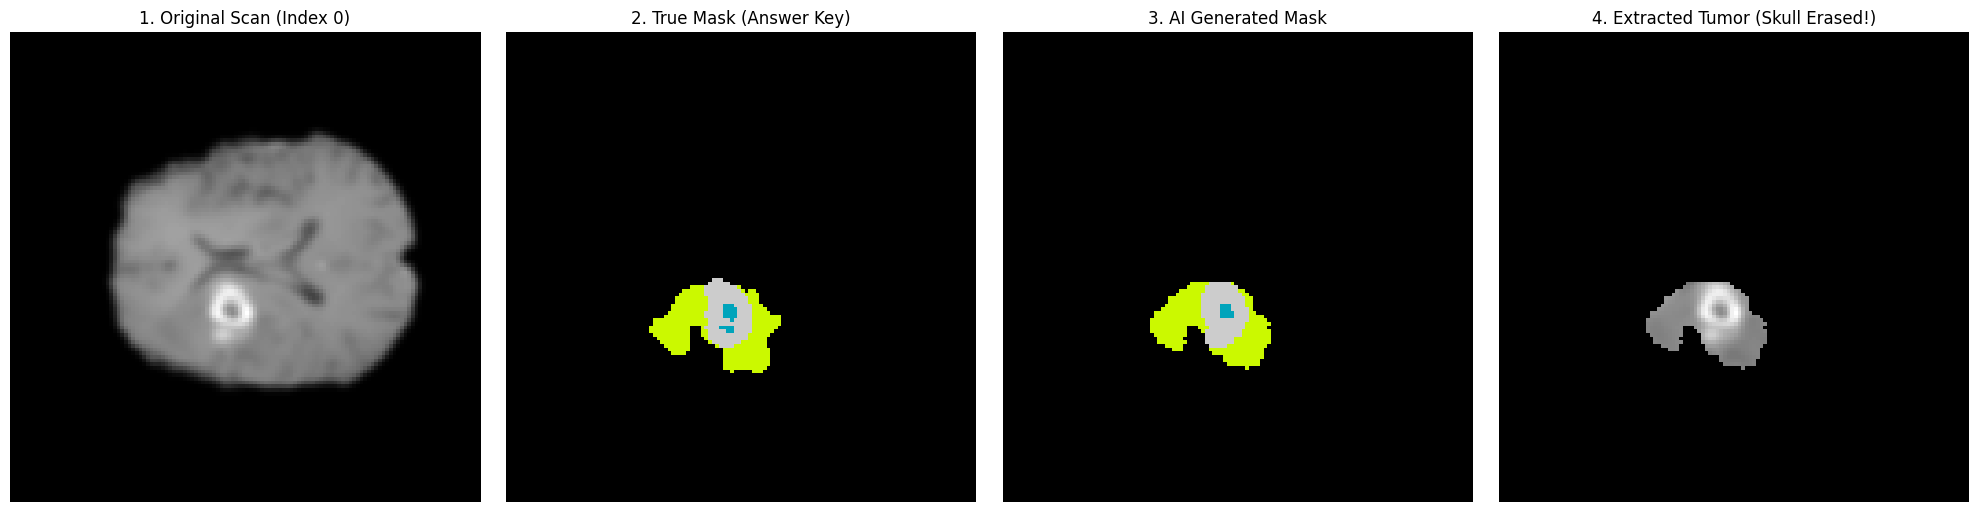

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

print("--- 1. THE FINAL EXAM (TEST SET) ---")
# Grade the model on the unseen test dataset
results = unet_model.evaluate(test_dataset)
print(f"Test Loss: {results[0]:.4f}")
print(f"Test Accuracy: {results[1]:.4f}")
print(f"Test Precision: {results[2]:.4f}")
print(f"Test Recall: {results[3]:.4f}")

print("\n--- 2. SURGICAL EXTRACTION (VISUALIZATION) ---")
# 1. Grab ONE batch of images and masks from the Test Set
sample_images, sample_masks = next(iter(test_dataset))


image_index = 0
# =====================================================================


single_image_tensor = sample_images[image_index : image_index+1]
original_image_2d = single_image_tensor[0].numpy().squeeze()

# 2. CREATE THE MASK (The AI predicts)
raw_prediction = unet_model.predict(single_image_tensor)


predicted_mask = tf.argmax(raw_prediction, axis=-1)[0].numpy()

true_mask = tf.argmax(sample_masks[image_index], axis=-1).numpy()


cookie_cutter = (predicted_mask > 0).astype(np.float32)

# 4. EXTRACT THE TUMOR!
extracted_tumor = original_image_2d * cookie_cutter

#
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

# Image 1: The Original
axes[0].imshow(original_image_2d, cmap='gray')
axes[0].set_title(f"1. Original Scan (Index {image_index})")
axes[0].axis('off')

# Image 2: The Doctor's True Mask
axes[1].imshow(true_mask, cmap='nipy_spectral', vmin=0, vmax=3)
axes[1].set_title("2. True Mask (Answer Key)")
axes[1].axis('off')

# Image 3: The AI's Prediction
axes[2].imshow(predicted_mask, cmap='nipy_spectral', vmin=0, vmax=3)
axes[2].set_title("3. AI Generated Mask")
axes[2].axis('off')

# Image 4: The Extracted Tumor
axes[3].imshow(extracted_tumor, cmap='gray')
axes[3].set_title("4. Extracted Tumor (Skull Erased!)")
axes[3].axis('off')

plt.tight_layout()
plt.show()


In [ ]:
print("Test image MAX value:", original_image_2d.max())

Test image MAX value: 0.74509805


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step


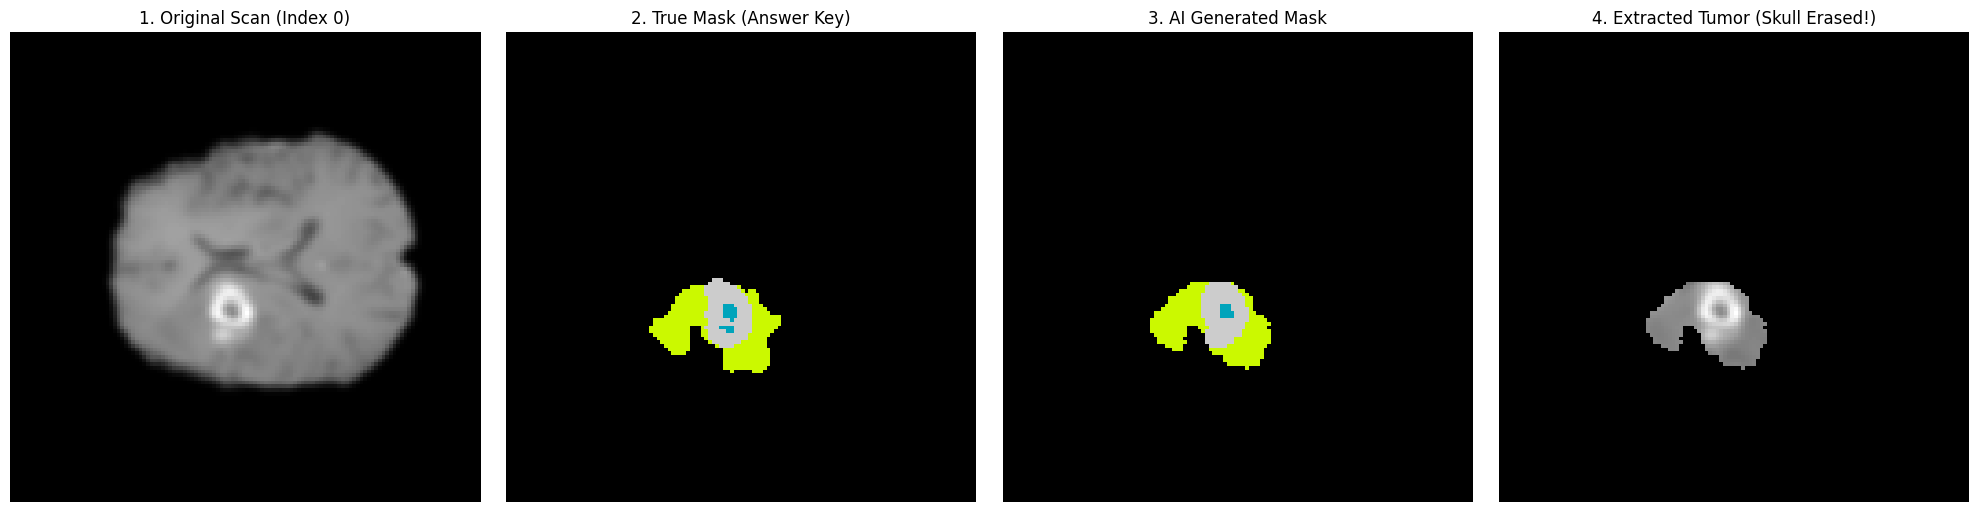

In [ ]:
sample_images, sample_masks = next(iter(test_dataset))


image_index = 0


single_image_tensor = sample_images[image_index : image_index+1]
original_image_2d = single_image_tensor[0].numpy().squeeze()


raw_prediction = unet_model.predict(single_image_tensor)


predicted_mask = tf.argmax(raw_prediction, axis=-1)[0].numpy()

true_mask = tf.argmax(sample_masks[image_index], axis=-1).numpy()


cookie_cutter = (predicted_mask > 0).astype(np.float32)


extracted_tumor = original_image_2d * cookie_cutter


fig, axes = plt.subplots(1, 4, figsize=(20, 5))


axes[0].imshow(original_image_2d, cmap='gray')
axes[0].set_title(f"1. Original Scan (Index {image_index})")
axes[0].axis('off')

# Image 2: The Doctor's True Mask
axes[1].imshow(true_mask, cmap='nipy_spectral', vmin=0, vmax=3)
axes[1].set_title("2. True Mask (Answer Key)")
axes[1].axis('off')

# Image 3: The AI's Prediction
axes[2].imshow(predicted_mask, cmap='nipy_spectral', vmin=0, vmax=3)
axes[2].set_title("3. AI Generated Mask")
axes[2].axis('off')

# Image 4: The Extracted Tumor
axes[3].imshow(extracted_tumor, cmap='gray')
axes[3].set_title("4. Extracted Tumor (Skull Erased!)")
axes[3].axis('off')

plt.tight_layout()
plt.show()

In [ ]:
unet_model.save("/content/drive/MyDrive/best_unet_model.keras")

In [ ]:
import numpy as np
import tensorflow as tf


image_batch, _ = next(iter(test_dataset.shuffle(100).take(1)))
patient_image = image_batch[0:1]


prediction = unet_model.predict(patient_image, verbose=0)
predicted_mask = tf.argmax(prediction, axis=-1)[0].numpy()


total_tumor_pixels = np.sum(predicted_mask > 0)

print("========================================")
print(" 🏥 QUICK AI DIAGNOSIS")
print("========================================")

if total_tumor_pixels == 0:
    print("🟢 Diagnosis: Healthy / No Brain Tumor Detected.")
else:
    print("🔴 Diagnosis: Brain Tumor (Glioma) Detected.")
    print("\nSpecific Tumor Sub-regions present:")

    if np.any(predicted_mask == 1):
        print("  Necrotic Core (Dead tissue found)")


    if np.any(predicted_mask == 2):
        print(" Edema (Swelling found around tumor)")

    if np.any(predicted_mask == 3):
        print("   Enhancing Tumor (Active growing cancer found)")

print("========================================")


 🏥 QUICK AI DIAGNOSIS
🔴 Diagnosis: Brain Tumor (Glioma) Detected.

Specific Tumor Sub-regions present:
 Edema (Swelling found around tumor)


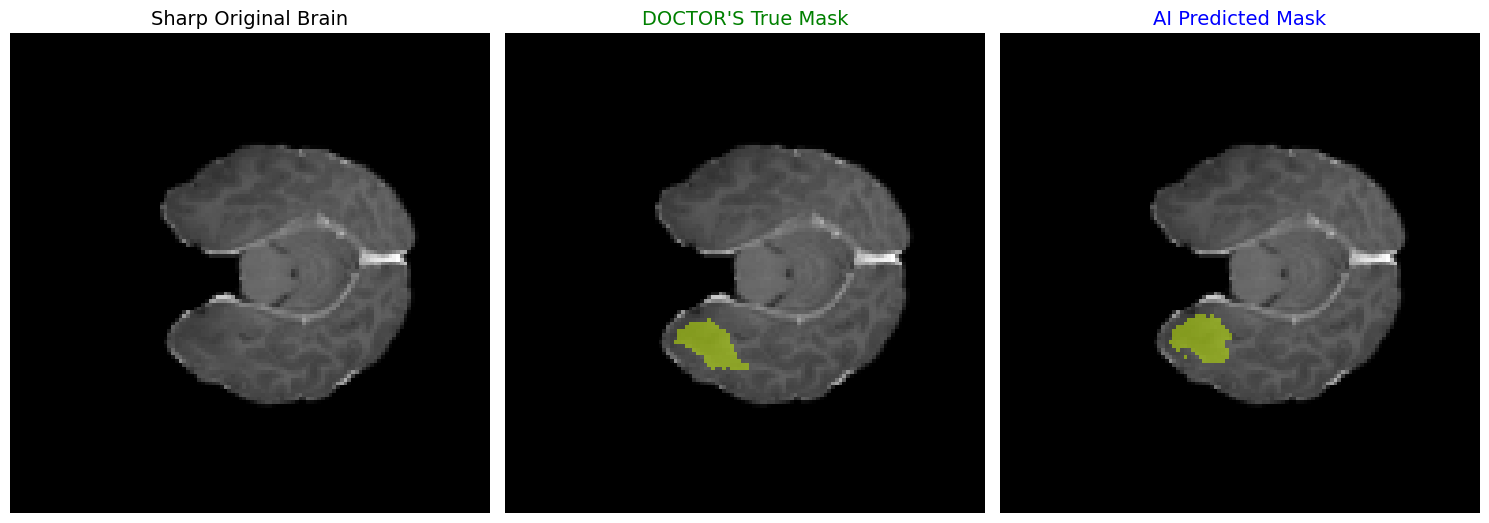

In [ ]:
import cv2
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import glob
import random
import os


mask_paths = glob.glob('masks_resized/*.png')
random_mask_path = random.choice(mask_paths)
filename = os.path.basename(random_mask_path)


sharp_image_path = os.path.join('images_resized', filename)
sharp_img = cv2.imread(sharp_image_path, cv2.IMREAD_GRAYSCALE)

# B. The BLURRED Image
blurred_image_path = os.path.join('processed_images', filename)
blurred_img = cv2.imread(blurred_image_path, cv2.IMREAD_GRAYSCALE)
# Normalize for the AI
ai_input = (blurred_img.astype(np.float32) / 255.0).reshape(1, 128, 128, 1)

# C. The TRUE MASK (The Doctor's Answer Key)
true_mask = cv2.imread(random_mask_path, cv2.IMREAD_GRAYSCALE)
true_mask = np.where(true_mask == 4, 3, true_mask) # Fix the BraTS class bug


prediction = unet_model.predict(ai_input, verbose=0)
predicted_mask = tf.argmax(prediction, axis=-1)[0].numpy()


transparent_true = np.ma.masked_where(true_mask == 0, true_mask)
transparent_pred = np.ma.masked_where(predicted_mask == 0, predicted_mask)


plt.figure(figsize=(15, 6))


plt.subplot(1, 3, 1)
plt.title("Sharp Original Brain", fontsize=14)
plt.imshow(sharp_img, cmap='gray')
plt.axis('off')


plt.subplot(1, 3, 2)
plt.title("DOCTOR'S True Mask", fontsize=14, color='green')
plt.imshow(sharp_img, cmap='gray')
plt.imshow(transparent_true, cmap='nipy_spectral', alpha=0.5, vmin=0, vmax=3)
plt.axis('off')

plt.subplot(1, 3, 3)
plt.title("AI Predicted Mask", fontsize=14, color='blue')
plt.imshow(sharp_img, cmap='gray')
plt.imshow(transparent_pred, cmap='nipy_spectral', alpha=0.5, vmin=0, vmax=3)
plt.axis('off')

plt.tight_layout()
plt.show()


In [ ]:
import glob
import os
import cv2
import numpy as np
import tensorflow as tf
from skimage import measure
import plotly.graph_objects as go

print("==================================================")
print(" 🌈 ENHANCED INLINE 3D TUMOR VIEWER")
print("==================================================")

patient_id = "BraTS2021_00000"

# 1. Gather all slices
search_pattern = os.path.join('images_resized', f"{patient_id}_slice_*.png")
patient_slices = sorted(glob.glob(search_pattern))

if len(patient_slices) == 0:
    print("❌ Images not found.")
else:
    print(f"✅ Scanning {len(patient_slices)} slices...")

    stack_brains = []
    stack_tumors = []

    for sharp_path in patient_slices:

        sharp_img = cv2.imread(sharp_path, cv2.IMREAD_GRAYSCALE)
        stack_brains.append(sharp_img)

        # Load Blurred Brain & Predict
        blurred_path = sharp_path.replace('images_resized', 'processed_images')
        blurred_img = cv2.imread(blurred_path, cv2.IMREAD_GRAYSCALE)
        ai_input = (blurred_img.astype(np.float32) / 255.0).reshape(1, 128, 128, 1)

        prediction = unet_model.predict(ai_input, verbose=0)
        pred_mask = tf.argmax(prediction, axis=-1)[0].numpy()
        stack_tumors.append(pred_mask)

    # 2. Convert to 3D Arrays
    vol_brain = np.array(stack_brains)
    vol_tumor = np.array(stack_tumors)

    print("🧊 Generating 3D Colors (Optimized for Notebook display)...")

    fig = go.Figure()


    if np.sum(vol_brain > 10) > 0:
        v, f, _, _ = measure.marching_cubes((vol_brain > 10).astype(np.uint8), level=0.5, step_size=4)
        fig.add_trace(go.Mesh3d(x=v[:, 0], y=v[:, 1], z=v[:, 2], i=f[:, 0], j=f[:, 1], k=f[:, 2],
                                color='lightgray', opacity=0.45, name='Brain Anatomy'))

    # --- 2. TUMOR TYPE 1: NECROTIC CORE (Blue, Solid) ---
    if np.sum(vol_tumor == 1) > 0:
        v, f, _, _ = measure.marching_cubes((vol_tumor == 1).astype(np.uint8), level=0.5, step_size=2)
        fig.add_trace(go.Mesh3d(x=v[:, 0], y=v[:, 1], z=v[:, 2], i=f[:, 0], j=f[:, 1], k=f[:, 2],
                                color='blue', opacity=0.8, name='Necrotic Core'))

    # --- 3. TUMOR TYPE 2: EDEMA / SWELLING (Green, Transparent) ---
    # We make edema transparent (0.3) so you can see the red and blue hiding inside it!
    if np.sum(vol_tumor == 2) > 0:
        v, f, _, _ = measure.marching_cubes((vol_tumor == 2).astype(np.uint8), level=0.5, step_size=2)
        fig.add_trace(go.Mesh3d(x=v[:, 0], y=v[:, 1], z=v[:, 2], i=f[:, 0], j=f[:, 1], k=f[:, 2],
                                color='green', opacity=0.3, name='Edema (Swelling)'))

    # --- 4. TUMOR TYPE 3: ACTIVE TUMOR (Red, Solid) ---
    if np.sum(vol_tumor == 3) > 0:
        v, f, _, _ = measure.marching_cubes((vol_tumor == 3).astype(np.uint8), level=0.5, step_size=2)
        fig.add_trace(go.Mesh3d(x=v[:, 0], y=v[:, 1], z=v[:, 2], i=f[:, 0], j=f[:, 1], k=f[:, 2],
                                color='red', opacity=1.0, name='Active Tumor'))

    # Final Viewer Settings (Restoring the correct squashed proportions)
    fig.update_layout(
        title=f"3D Multi-Color Tumor Map: {patient_id}",
        scene=dict(
            xaxis_title='Width (X)',
            yaxis_title='Depth (Y)',
            zaxis_title='Slices (Z)',
            aspectmode='data' # This tells Plotly to draw it exactly as it physically exists
        ),
        margin=dict(l=0, r=0, b=0, t=40)
    )

    print("✅ Ready! Use your mouse to rotate and zoom below:")
    fig.show()


 🌈 ENHANCED INLINE 3D TUMOR VIEWER
✅ Scanning 47 slices...
🧊 Generating 3D Colors (Optimized for Notebook display)...
✅ Ready! Use your mouse to rotate and zoom below:
